# Temporal graph modeling

**Analytical question:** Represent changing player interactions.

**Stages in this notebook:** Lagged features; identity edges; graph embeddings; recurrent, convolutional and masked-attention alternatives.

This is one complete analytical workflow. Its helper functions and intermediate steps are sections within the notebook, rather than separate notebooks. All required code is inline: downloading, kloppy loading, reshaping, plotting and method calculations. No local `.py` helper or prior notebook session is required. Set `DATA_ROOT` below to reuse another cache; absent data are downloaded from the pinned SkillCorner open-data revision.

Run top to bottom and inspect each intermediate table and visual before interpreting the final result. Some calculations are explicitly teaching baselines or synthetic training checks, not exact research/provider implementations or measured soccer-model performance. Dependencies are listed in the repository requirements and the imports below.


**Reading order:** follow the numbered stages. Each helper is introduced before its first use, then its intermediate output is inspected. The final result comes after those stages.

## 1. Imports and data location

In [1]:
from pathlib import Path
import json, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
from IPython.display import display
from kloppy import skillcorner

# Change DATA_ROOT to use an existing cache elsewhere. No local Python modules are imported.
candidates=[Path.cwd(),*Path.cwd().parents]
ROOT=next((p for p in candidates if (p/'data/1925299/1925299_match.json').exists()),Path.cwd())
DATA_ROOT=ROOT/'data/1925299'


## 2. Inline ingestion and plotting helpers

In [2]:
def ensure_sample(destination):
    """Download only missing data files. Tracking is bounded to 9000 source records."""
    destination.mkdir(parents=True,exist_ok=True)
    revision='4340d274572876239c154c90bc507a9b3250a656'
    base=f'https://raw.githubusercontent.com/SkillCorner/opendata/{revision}/data/matches/1925299/'
    for suffix in ['match.json','dynamic_events.csv','phases_of_play.csv']:
        name='1925299_'+suffix;target=destination/name
        if not target.exists():
            with urllib.request.urlopen(base+name,timeout=90) as response:target.write_bytes(response.read())
    name='1925299_tracking_extrapolated.jsonl';target=destination/name
    if not target.exists():
        url=base.replace('raw.githubusercontent.com/','media.githubusercontent.com/media/')+name
        temporary=destination/(name+'.partial')
        with urllib.request.urlopen(url,timeout=90) as response,temporary.open('wb') as output:
            count=0
            for line in response:
                if line.strip():
                    json.loads(line);output.write(line);count+=1
                if count>=9000:break
        temporary.replace(target)

def read_tracking(destination):
    """Load kloppy coordinates and explicitly reshape player columns to rows."""
    dataset=skillcorner.load(meta_data=destination/'1925299_match.json',raw_data=destination/'1925299_tracking_extrapolated.jsonl',coordinates='skillcorner')
    wide=dataset.to_df()
    metadata=json.loads((destination/'1925299_match.json').read_text(encoding='utf-8'))
    raw=[json.loads(line) for line in (destination/'1925299_tracking_extrapolated.jsonl').read_text().splitlines() if line.strip()]
    player_possession={r['frame']:str(r.get('possession',{}).get('player_id')) for r in raw}
    visibility={(r['frame'],str(p['player_id'])):p.get('is_detected') for r in raw for p in r.get('player_data',[])}
    parts=[]
    for p in metadata['players']:
        pid=str(p['id'])
        if f'{pid}_x' not in wide:continue
        part=wide[['period_id','frame_id','timestamp','ball_owning_team_id',f'{pid}_x',f'{pid}_y']].copy()
        part.columns=['period_id','frame_id','timestamp','team_in_possession','x','y']
        part['player_id']=pid;part['team_id']=p['team_id'];part['name']=p['short_name'];parts.append(part)
    tracking=pd.concat(parts,ignore_index=True)
    tracking['seconds']=tracking.timestamp.dt.total_seconds()
    tracking['player_in_possession']=tracking.frame_id.map(player_possession)
    tracking['is_detected']=[visibility.get((f,p)) for f,p in zip(tracking.frame_id,tracking.player_id)]
    tracking=tracking.sort_values(['player_id','period_id','frame_id'])
    return dataset,wide,tracking,metadata,raw

def pitch(ax=None):
    """Draw a 105 by 68 metre pitch in native centered coordinates."""
    if ax is None:_,ax=plt.subplots(figsize=(9,5.5))
    ax.set_facecolor('#eef3ed')
    ax.add_patch(Rectangle((-52.5,-34),105,68,fill=False,color='#597063'))
    ax.plot([0,0],[-34,34],c='#597063');ax.add_patch(Circle((0,0),9.15,fill=False,color='#597063'))
    for x in [-52.5,36]:ax.add_patch(Rectangle((x,-20.16),16.5,40.32,fill=False,color='#597063'))
    ax.set(xlim=(-55,55),ylim=(-36,36),aspect='equal',xlabel='x (m)',ylabel='y (m)')
    return ax


## 3. Read the real sample

In [3]:
ensure_sample(DATA_ROOT)
dataset,wide,tracking,metadata,raw=read_tracking(DATA_ROOT)
events=pd.read_csv(DATA_ROOT/'1925299_dynamic_events.csv')
phases=pd.read_csv(DATA_ROOT/'1925299_phases_of_play.csv')
observed=tracking.dropna(subset=['x','y'])
complete=observed.groupby(['period_id','frame_id']).size()
frame_id=int(complete[complete.eq(22)].index[20][1])
snapshot=observed[observed.frame_id.eq(frame_id)].copy()
keepers={str(p['id']) for p in metadata['players'] if 'goalkeeper' in p['player_role']['name'].lower()}
role_labels={str(p['id']):p['player_role']['acronym'] for p in metadata['players']}
assert not tracking.duplicated(['period_id','frame_id','player_id']).any()
display(tracking[['period_id','frame_id','player_id','x','y','is_detected']].head(3))
print('Real bounded sample. Diagnostic frame:',frame_id)


,period_id,frame_id,player_id,x,y,is_detected
67683,1,40,11897,-22.46,-10.06,True
67684,1,41,11897,-22.46,-10.06,True
67685,1,42,11897,-22.47,-10.05,True


Real bounded sample. Diagnostic frame: 61


## 4. Create historical displacement features

Inspect lagged rows and gap masks before connecting graph snapshots.

,player_id,frame_id,lag_frame,dx_1s,dy_1s
67693,11897,50,40.0,-0.20,0.15
67694,11897,51,41.0,-0.24,0.20
67695,11897,52,42.0,-0.27,0.24
67696,11897,53,43.0,-0.31,0.30
67697,11897,54,44.0,-0.36,0.35


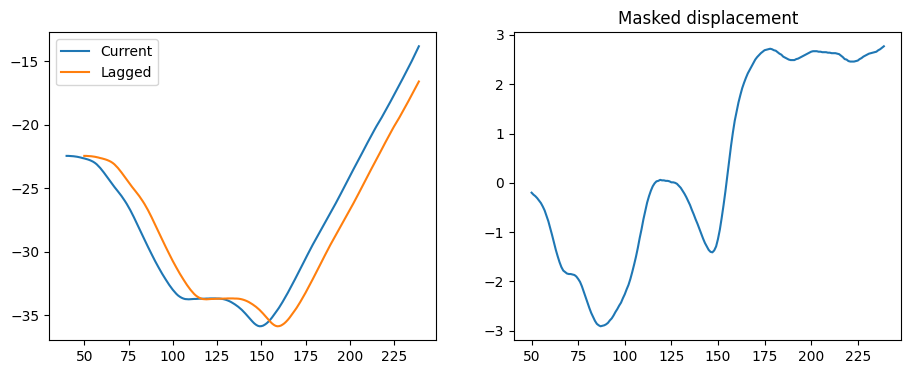

In [4]:
history=tracking.sort_values(['player_id','period_id','frame_id']).copy();groups=history.groupby(['player_id','period_id'])
history['lag_frame']=groups.frame_id.shift(10);history['lag_time']=groups.seconds.shift(10)
valid=history.frame_id.sub(history.lag_frame).eq(10)&np.isclose(history.seconds-history.lag_time,1)
history['dx_1s']=(history.x-groups.x.shift(10)).where(valid);history['dy_1s']=(history.y-groups.y.shift(10)).where(valid)
display(history[['player_id','frame_id','lag_frame','dx_1s','dy_1s']].dropna().head())
player=history[history.dx_1s.notna()].player_id.iloc[0];g=history[history.player_id.eq(player)].head(200)
fig,axs=plt.subplots(1,2,figsize=(11,4));axs[0].plot(g.frame_id,g.x,label='Current');axs[0].plot(g.frame_id,g.x.shift(10),label='Lagged');axs[0].legend();axs[1].plot(g.frame_id,g.dx_1s);axs[1].set_title('Masked displacement');plt.show()

## 5. Build causal identity edges

Only link consecutive observations of the same player within the same period.

,player_id,period,source_frame,target_frame,dt
0,11897,1,40,41,0.1
1,11897,1,41,42,0.1
2,11897,1,42,43,0.1
3,11897,1,43,44,0.1
4,11897,1,44,45,0.1


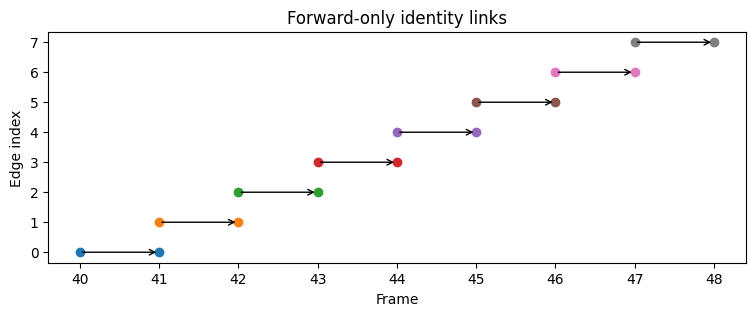

In [5]:
temporal=[]
for (pid,period),g in observed.groupby(['player_id','period_id']):
    g=g.sort_values('frame_id')
    for a,b in zip(g.itertuples(),list(g.itertuples())[1:]):
        if b.frame_id-a.frame_id==1 and 0<b.seconds-a.seconds<.2:temporal.append((pid,period,a.frame_id,b.frame_id,b.seconds-a.seconds))
temporal=pd.DataFrame(temporal,columns=['player_id','period','source_frame','target_frame','dt']);assert temporal.target_frame.gt(temporal.source_frame).all();display(temporal.head())
fig,ax=plt.subplots(figsize=(9,3))
for i,r in enumerate(temporal.head(8).itertuples()):ax.annotate('',xy=(r.target_frame,i),xytext=(r.source_frame,i),arrowprops=dict(arrowstyle='->'));ax.scatter([r.source_frame,r.target_frame],[i,i])
ax.set(xlabel='Frame',ylabel='Edge index',title='Forward-only identity links');plt.show()

## 6. Build and encode spatial graphs

Prepare the per-frame representation before introducing temporal encoders. Random graph weights illustrate tensor mechanics.

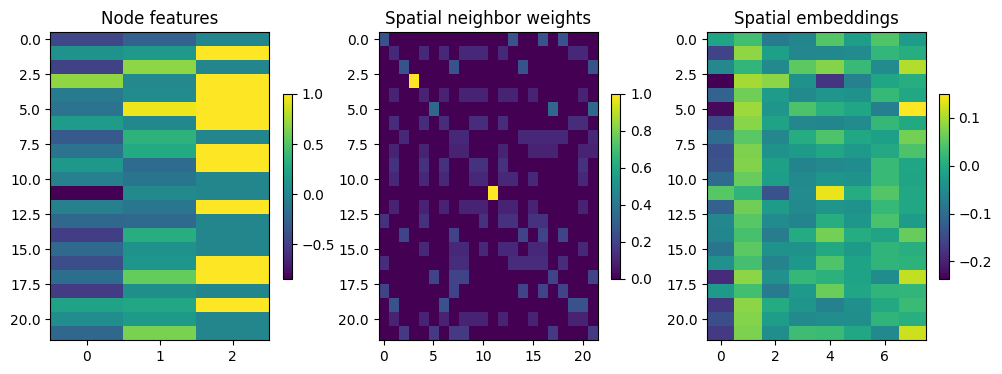

In [6]:
def make_graph(nodes,radius=15):
    nodes=nodes.sort_values('player_id');position=nodes[['x','y']].to_numpy()
    X=np.c_[position/np.array([52.5,34]),nodes.team_id.eq(1802).astype(float)]
    distance=np.linalg.norm(position[:,None]-position[None,:],axis=-1)
    A=(distance<=radius).astype(float) # includes self loops
    A=A/A.sum(axis=1,keepdims=True)
    return X,A,nodes.player_id.to_numpy()

def encode(X,A,W):return np.tanh(A@X@W)
X,A,ids=make_graph(snapshot);rng=np.random.default_rng(4);W=rng.normal(0,.1,(X.shape[1],8));hidden=encode(X,A,W)
fig,axs=plt.subplots(1,3,figsize=(12,4))
for ax,data,title in zip(axs,[X,A,hidden],['Node features','Spatial neighbor weights','Spatial embeddings']):im=ax.imshow(data,aspect='auto');ax.set_title(title);fig.colorbar(im,ax=ax,shrink=.6)
plt.show()

## 7. Stack historical graph embeddings

Choose a continuous clip and pool its spatial embeddings into a history matrix.

,0,1,2,3,4,5,6,7
0,-0.110701,0.059873,-0.030675,-0.026829,-0.009847,-0.025431,0.002996,0.026831
1,-0.110689,0.059887,-0.030772,-0.026843,-0.009743,-0.025423,0.003010,0.026858
2,-0.110656,0.059904,-0.030903,-0.026879,-0.009608,-0.025417,0.003044,0.026871
3,-0.110638,0.059926,-0.031053,-0.026902,-0.009448,-0.025403,0.003065,0.026913
4,-0.109979,0.059516,-0.031176,-0.026393,-0.008816,-0.025029,0.002782,0.027281


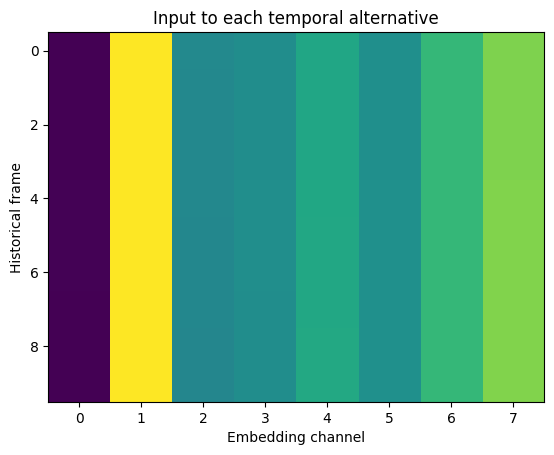

In [7]:
available=observed.groupby('frame_id').size();available=set(available[available.eq(22)].index);start=next(f for f in sorted(available) if all(f+j in available for j in range(10)))
Z=[]
for frame in range(start,start+10):
    Xi,Ai,_=make_graph(observed[observed.frame_id.eq(frame)]);Z.append(encode(Xi,Ai,W).mean(axis=0))
Z=np.array(Z);d=Z.shape[1];display(pd.DataFrame(Z).head());plt.imshow(Z,aspect='auto');plt.xlabel('Embedding channel');plt.ylabel('Historical frame');plt.title('Input to each temporal alternative');plt.show()

## 8. Alternative A: inspect recurrent state updates

Inspect the first update before running the recurrent loop. This is a plain tanh RNN, not a trained GRU.

,input_projection,initial_state,updated_state
0,0.012791,0.0,0.012791
1,-0.016130,0.0,-0.016129
2,0.007115,0.0,0.007115
3,-0.001300,0.0,-0.001300
4,-0.010545,0.0,-0.010544
5,0.023525,0.0,0.023521
6,0.001033,0.0,0.001033
7,-0.003637,0.0,-0.003637


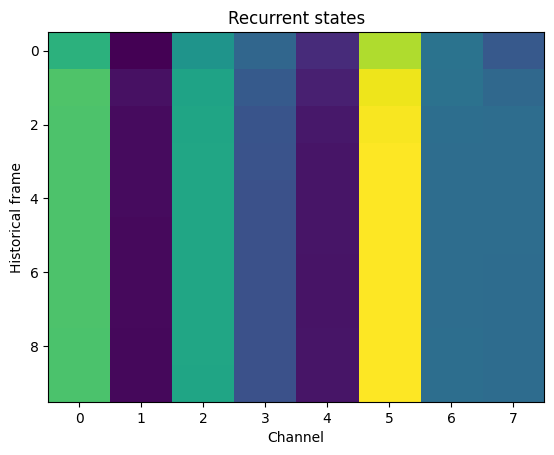

In [8]:
def recurrent_states(Z,U,R):
    state=np.zeros(R.shape[0]);history=[]
    for z in Z:state=np.tanh(z@U+state@R);history.append(state.copy())
    return np.array(history)
rng=np.random.default_rng(9);U=rng.normal(0,.1,(d,d));R=rng.normal(0,.1,(d,d));first_input=Z[0]@U;first_state=np.tanh(first_input)
display(pd.DataFrame({'input_projection':first_input,'initial_state':np.zeros(d),'updated_state':first_state}))
states=recurrent_states(Z,U,R);plt.imshow(states,aspect='auto');plt.xlabel('Channel');plt.ylabel('Historical frame');plt.title('Recurrent states');plt.show()

## 9. Alternative B: inspect causal convolution contributions

Display current and lagged contributions before the filtered sequence.

,0,1,2,3,4,5,6,7
current contribution,-0.066066,0.035925,-0.019479,-0.016083,-0.004578,-0.015036,0.001855,0.016499
lag 1 contribution,-0.033043,0.017946,-0.009634,-0.008029,-0.002404,-0.007529,0.000916,0.008214
lag 2 contribution,-0.011017,0.005977,-0.003180,-0.002673,-0.000836,-0.002513,0.000302,0.002727


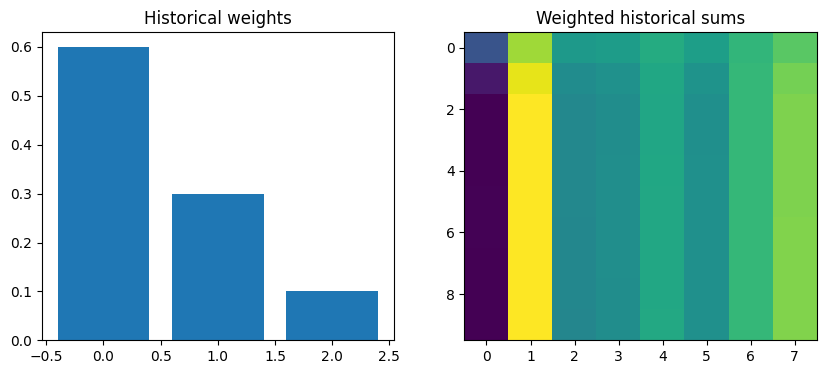

In [9]:
def causal_convolution(Z,kernel):
    result=[];contributions=[]
    for t in range(len(Z)):
        pieces=[kernel[k]*Z[t-k] for k in range(min(len(kernel),t+1))]
        contributions.append(pieces);result.append(np.sum(pieces,axis=0))
    return np.array(result),contributions
kernel=np.array([.6,.3,.1]);filtered,pieces=causal_convolution(Z,kernel)
display(pd.DataFrame(np.array(pieces[-1]),index=['current contribution','lag 1 contribution','lag 2 contribution']))
fig,axs=plt.subplots(1,2,figsize=(10,4));axs[0].bar(range(3),kernel);axs[0].set_title('Historical weights');axs[1].imshow(filtered,aspect='auto');axs[1].set_title('Weighted historical sums');plt.show()

## 10. Alternative C: inspect attention scores and causal mask

Do not normalize until the future mask has been applied.

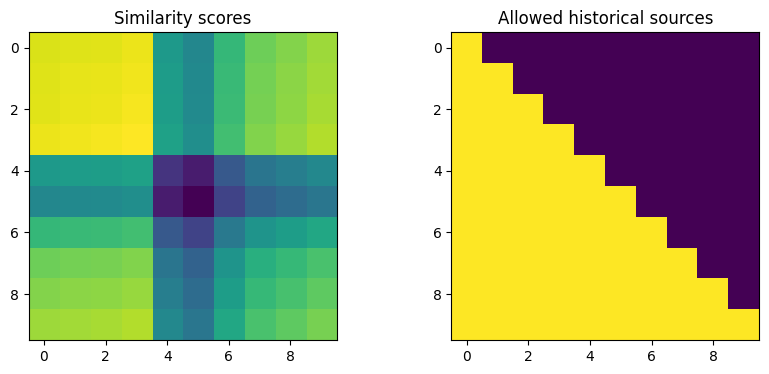

,0,1,2,3,4,5,6,7,8,9
0,1.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
1,0.500000,0.500000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
2,0.333333,0.333333,0.333334,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
3,0.250000,0.250000,0.250000,0.250000,0.000000,0.0,0.0,0.0,0.0,0.0
4,0.200001,0.200001,0.200002,0.200002,0.199994,0.0,0.0,0.0,0.0,0.0


In [10]:
scores=Z@Z.T/np.sqrt(d);allowed=np.tril(np.ones_like(scores,dtype=bool));masked=np.where(allowed,scores,-np.inf)
fig,axs=plt.subplots(1,2,figsize=(10,4));axs[0].imshow(scores);axs[0].set_title('Similarity scores');axs[1].imshow(allowed);axs[1].set_title('Allowed historical sources');plt.show()
weights=np.exp(masked-masked.max(axis=1,keepdims=True));weights/=weights.sum(axis=1,keepdims=True);context=weights@Z
assert np.all(weights[~allowed]==0) and np.allclose(weights.sum(axis=1),1)
display(pd.DataFrame(weights).head())

## 11. Final output: compare the temporal representations

The same historical graph input has now passed through three explicit alternative encoders.

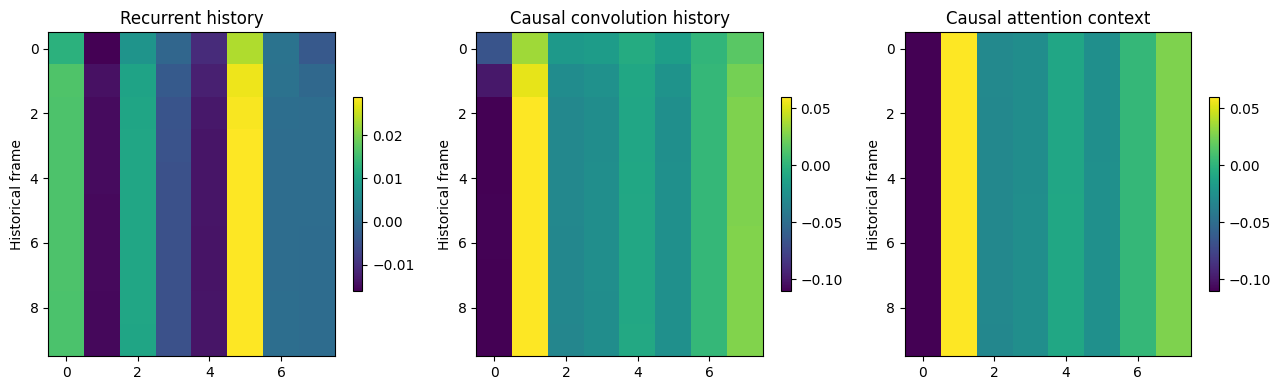

In [11]:
fig,axs=plt.subplots(1,3,figsize=(13,4))
for ax,data,title in zip(axs,[states,filtered,context],['Recurrent history','Causal convolution history','Causal attention context']):im=ax.imshow(data,aspect='auto');ax.set_title(title);ax.set_ylabel('Historical frame');fig.colorbar(im,ax=ax,shrink=.6)
plt.tight_layout();plt.show()

## Interpretation and limitations

These are random/fixed-parameter forward calculations, not trained EPV or forecasts. Identity-edge message passing is another architecture, not equivalent to temporal pooling. Use causal preprocessing, complete identity handling and match-level evaluation; attention weights do not establish causal importance.